In [1]:
# Import Python Libraries
import numpy as np
import scipy as sp
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
import os

print("Joriy papka:", os.getcwd())
print("bank+marketing papkasi ichidagi fayllar:")

for root, dirs, files in os.walk("bank+marketing"):
    for file in files:
        print(os.path.join(root, file))

Joriy papka: d:\shokh_005\Data Analysis
bank+marketing papkasi ichidagi fayllar:
bank+marketing\.DS_Store
bank+marketing\.Rhistory
bank+marketing\._.DS_Store
bank+marketing\._bank-additional
bank+marketing\bank-additional-full.csv
bank+marketing\bank-additional-names.txt
bank+marketing\bank-additional.csv
bank+marketing\bank-full.csv
bank+marketing\bank-names.txt
bank+marketing\bank.csv


In [3]:

# Import Python Libraries
import numpy as np
import scipy as sp
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

# Dataset manzili
data_path = 'bank+marketing/bank-full.csv'

# Datasetni o'qish
df = pd.read_csv(data_path, sep=';')

# Dastlabki 5 qatorni ko'rish
df.head()


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
print("Qatorlar va ustunlar soni:", df.shape)
print("Ustunlar:", df.columns.tolist())

Qatorlar va ustunlar soni: (45211, 17)
Ustunlar: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


In [5]:
# dastlabki 5 qatorini ko'rish
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [6]:
# oxirgi 10 qatorini ko'rish
df.tail(10)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45201,53,management,married,tertiary,no,583,no,no,cellular,17,nov,226,1,184,4,success,yes
45202,34,admin.,single,secondary,no,557,no,no,cellular,17,nov,224,1,-1,0,unknown,yes
45203,23,student,single,tertiary,no,113,no,no,cellular,17,nov,266,1,-1,0,unknown,yes
45204,73,retired,married,secondary,no,2850,no,no,cellular,17,nov,300,1,40,8,failure,yes
45205,25,technician,single,secondary,no,505,no,yes,cellular,17,nov,386,2,-1,0,unknown,yes
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no


In [7]:
# Ma'lum ustun ma'lumot turini tekshirish
df['duration'].dtype

dtype('int64')

In [8]:
# Ustunlarning ma'lumot turlarini tekshirish
df.dtypes

age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object

In [9]:
# 1. Mijozlarni kasbi bo'yicha guruhlash
df_rank = df.groupby(["job"])

# Har bir kasb bo‘yicha mijozlar sonini chiqarish
print(df_rank.size())

# 2. "?" belgilarini NaN (bo'sh qiymat) bilan almashtirish
df.replace("?", np.nan, inplace=True)

# Har bir ustundagi bo‘sh qiymatlarni tekshirish
print(df.isnull().sum())

# 3. Hisob balansini float ma'lumot turiga o'tkazish
df["balance"] = df["balance"].astype("float")

# 4. Hisob balansi 12000 dan yuqori bo'lgan mijozlarni ajratish
df_sub = df[df["balance"] > 12000]

df_sub

job
admin.           5171
blue-collar      9732
entrepreneur     1487
housemaid        1240
management       9458
retired          2264
self-employed    1579
services         4154
student           938
technician       7597
unemployed       1303
unknown           288
dtype: int64
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
69,35,blue-collar,single,secondary,no,12223.0,yes,yes,unknown,5,may,177,1,-1,0,unknown,no
334,45,management,divorced,tertiary,no,24598.0,yes,no,unknown,5,may,313,3,-1,0,unknown,no
446,39,technician,single,unknown,no,45248.0,yes,no,unknown,6,may,1623,1,-1,0,unknown,yes
920,44,admin.,married,secondary,no,58544.0,yes,no,unknown,7,may,144,2,-1,0,unknown,no
2065,55,retired,married,secondary,no,18722.0,yes,no,unknown,12,may,128,2,-1,0,unknown,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44874,36,unemployed,married,secondary,no,17458.0,no,no,cellular,23,sep,390,2,-1,0,unknown,no
44972,36,technician,single,secondary,no,12264.0,no,no,cellular,11,oct,285,1,182,2,success,yes
45019,57,admin.,married,secondary,no,16873.0,no,no,cellular,14,oct,219,3,372,1,failure,no
45118,78,retired,married,primary,no,14204.0,no,no,cellular,26,oct,150,1,183,1,other,no


In [10]:
# Uy-joy krediti mavjud bo'lgan mijozlarni ajratish
df_f = df[df["housing"] == "yes"]

df_f

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143.0,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29.0,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2.0,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506.0,yes,no,unknown,5,may,92,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231.0,yes,no,unknown,5,may,139,1,-1,0,unknown,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45191,75,retired,divorced,tertiary,no,3810.0,yes,no,cellular,16,nov,262,1,183,1,failure,yes
45194,59,management,married,tertiary,no,138.0,yes,yes,cellular,16,nov,162,2,187,5,failure,no
45197,36,management,single,secondary,no,1511.0,yes,no,cellular,16,nov,270,1,-1,0,unknown,yes
45199,34,blue-collar,single,secondary,no,1475.0,yes,no,cellular,16,nov,1166,3,530,12,other,no


In [11]:
# Datasetning statistik tavsifini chiqarish
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [12]:
# Mijozlarning oilaviy holati bo'yicha sonini hisoblash
df["marital"].value_counts()

marital
married     27214
single      12790
divorced     5207
Name: count, dtype: int64

In [13]:
# Bank taklifiga berilgan javoblar soni
df["y"].value_counts()

y
no     39922
yes     5289
Name: count, dtype: int64

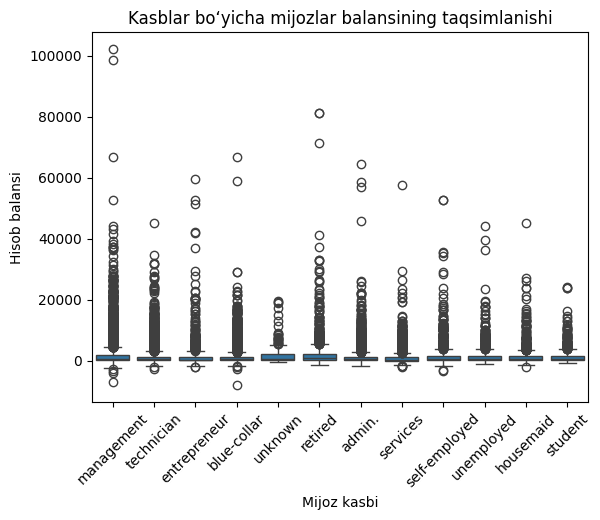

In [14]:
# Kasblar bo'yicha mijozlar balansini boxplot grafikda ko‘rsatish
sns.boxplot(x="job", y="balance", data=df)

# Grafik nomi va o'qlarini belgilash
plt.title("Kasblar bo‘yicha mijozlar balansining taqsimlanishi")
plt.xlabel("Mijoz kasbi")
plt.ylabel("Hisob balansi")

# Kasb nomlarini qiya ko'rsatish
plt.xticks(rotation=45)

plt.show()